# EDA dataset hiện tại của Gipbench

Notebook chuyển từ [báo cáo EDA HTML](index.html), giữ nguồn dataset, phương pháp,
sơ đồ xử lý, số liệu và kết luận. Các bảng và biểu đồ đã lưu sẵn trong output.

**Snapshot kiểm audio:** 2026-11-16T12:19:27.734010+07:00.  
**Bổ sung truy xuất nguồn:** 2026-11-16T13:12:31.673310+07:00.

Đọc lần lượt từ trên xuống. Mở bằng VS Code/Jupyter và chọn kernel Python 3 nếu muốn chạy lại.
Notebook đọc `summary.json` và các CSV trong cùng thư mục `reports/eda_current`;
các ô phân tích mặc định không tải dataset, không train và không quét lại toàn bộ audio.
Khi chia sẻ riêng file `.ipynb`, người nhận vẫn đọc được output đã lưu; để chạy lại cần gửi kèm
thư mục dữ liệu EDA hoặc mở notebook trong repo này.

Các biểu đồ dùng SVG; code chỉ dùng thư viện chuẩn Python cùng hàm `display` có sẵn trong kernel Jupyter.
Không cần pandas, matplotlib hay GPU để đọc và chạy các ô mặc định.

## 1. Cách đọc và mục tiêu

Ta cần trả lời: dữ liệu lấy từ đâu, đã xử lý ra sao, model thực sự học trên tập nào,
train có trùng dev/bench không và thiếu những loại ví dụ nào.

- **Nhãn / transcript:** câu chữ dùng làm đáp án cho một đoạn ghi âm.
- **Manifest:** danh sách audio, nhãn và metadata; một dòng được đếm là một câu.
- **ASR:** hệ nhận dạng giọng nói. **CS:** câu tiếng Việt có chen từ Anh.
- **Curate:** chọn và lọc dữ liệu theo quy tắc.
- **Pool sau Lhotse:** những câu đã qua chuyển định dạng và lọc kỹ thuật để lấy mẫu học.
- **Train / dev / bench:** dùng để học / chọn mô hình / đánh giá.
- **Span `<en>`:** phạm vi cụm từ được gắn là tiếng Anh, không phải thời lượng riêng của phần Anh.

Giờ của câu có Anh là thời lượng **toàn câu**, gồm cả tiếng Việt. Các giai đoạn có thể dùng lại cùng
audio; không cộng mọi hàng trong notebook để gọi đó là tổng số giờ âm thanh độc lập.

In [1]:
import csv
import hashlib
import json
import math
import statistics
import subprocess
import sys
import textwrap
from collections import Counter, defaultdict
from html import escape
from pathlib import Path

# Locate the report folder from the notebook directory or the repository root.
candidates = []
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([folder, folder / 'reports' / 'eda_current'])
REPORT_DIR = next((folder for folder in candidates if
                   (folder / 'summary.json').is_file() and
                   (folder / 'training_pool_rows.csv').is_file()), None)
if REPORT_DIR is None:
    raise FileNotFoundError('Mở notebook trong repo hoặc đặt cạnh summary.json và các CSV EDA.')
PROJECT_ROOT = REPORT_DIR.parent.parent
data = json.loads((REPORT_DIR / 'summary.json').read_text(encoding='utf-8'))
views = data['views']
lineage = data['dataset_lineage']

def read_csv(name):
    with (REPORT_DIR / name).open(encoding='utf-8-sig', newline='') as source:
        return list(csv.DictReader(source))

def fmt(value, digits=0):
    if value is None:
        return '—'
    if isinstance(value, (int, float)):
        return f'{value:,.{digits}f}'.replace(',', ' ')
    return str(value)

def show_html(markup, description='Bảng dữ liệu'):
    display({'text/html': markup, 'text/plain': description}, raw=True)

def table(headers, rows):
    head = ''.join(f'<th style="padding:8px;text-align:left;border-bottom:2px solid #bbcbd9">{escape(str(h))}</th>' for h in headers)
    body = ''.join('<tr>' + ''.join(f'<td style="padding:8px;border-bottom:1px solid #dce3e9;vertical-align:top;overflow-wrap:anywhere">{escape(str(v))}</td>' for v in row) + '</tr>' for row in rows)
    show_html('<div style="max-width:100%;overflow:auto"><table style="border-collapse:collapse;font:14px/1.5 Segoe UI,Arial,sans-serif">'
              + f'<thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>')

def bars(title, items, unit='', color='#286aab'):
    items = list(items)
    if not items:
        print(title + ': không có dữ liệu.')
        return
    width, row_height = 1100, 48
    height = 72 + row_height * len(items)
    maximum = max((float(value) for _, value in items), default=0) or 1
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" style="max-width:1100px;background:white;font-family:Segoe UI,Arial,sans-serif">',
             f'<title>{escape(title)}</title><rect width="100%" height="100%" fill="white"/>',
             f'<text x="15" y="30" font-size="20" font-weight="600" fill="#172a3a">{escape(title)}</text>']
    for index, (label, value) in enumerate(items):
        y = 68 + index * row_height
        lines = textwrap.wrap(str(label), 37, break_long_words=True)[:2]
        parts.append(f'<g><title>{escape(str(label))}: {escape(fmt(value, 2) + unit)}</title>')
        for offset, line in enumerate(lines):
            parts.append(f'<text x="15" y="{y - 2 + offset * 15}" font-size="13" fill="#172a3a">{escape(line)}</text>')
        parts.append(f'<rect x="310" y="{y - 13}" width="620" height="17" rx="2" fill="#e8eef3"/>')
        parts.append(f'<rect x="310" y="{y - 13}" width="{620 * float(value) / maximum:.2f}" height="17" rx="2" fill="{color}"/>')
        parts.append(f'<text x="945" y="{y + 1}" font-size="13" fill="#172a3a">{escape(fmt(value, 2) + unit)}</text></g>')
    parts.append('</svg>')
    display({'image/svg+xml': ''.join(parts), 'text/plain': title}, raw=True)

def flow(title, nodes):
    width, height = 1120, 205
    box_width = (width - 30 - 30 * (len(nodes) - 1)) / len(nodes)
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" style="max-width:1120px;background:white;font-family:Segoe UI,Arial,sans-serif">',
             f'<title>{escape(title)}</title><rect width="100%" height="100%" fill="white"/>',
             f'<text x="15" y="28" font-size="20" font-weight="600" fill="#172a3a">{escape(title)}</text>']
    for index, (label, value, note) in enumerate(nodes):
        x = 15 + index * (box_width + 30)
        parts.append(f'<rect x="{x}" y="50" width="{box_width}" height="140" rx="7" fill="#edf4fa" stroke="#bed1e1"/>')
        for offset, line in enumerate(textwrap.wrap(label, max(18, int(box_width / 8)))[:2]):
            parts.append(f'<text x="{x+12}" y="{73+offset*17}" font-size="13" fill="#4b6173">{escape(line)}</text>')
        parts.append(f'<text x="{x+12}" y="122" font-size="20" font-weight="600" fill="#172a3a">{escape(str(value))}</text>')
        for offset, line in enumerate(textwrap.wrap(str(note), max(18, int(box_width / 8)))[:2]):
            parts.append(f'<text x="{x+12}" y="{148+offset*17}" font-size="13" fill="#172a3a">{escape(line)}</text>')
        if index < len(nodes) - 1:
            arrow = x + box_width + 6
            parts.append(f'<path d="M{arrow} 120h17m-6 -5l6 5l-6 5" fill="none" stroke="#286aab" stroke-width="2"/>')
    parts.append('</svg>')
    display({'image/svg+xml': ''.join(parts), 'text/plain': title}, raw=True)

table(['Mục', 'Giá trị'], [
    ['Thư mục kết quả', str(REPORT_DIR)],
    ['Snapshot kiểm audio', data['generated_at']],
    ['Ngày bổ sung nguồn', lineage['documented_at']],
    ['Số file audio được kiểm', fmt(data['audio_files_checked'])],
    ['Số file audio thiếu', fmt(data['audio_files_missing'])],
])

Mục,Giá trị
Thư mục kết quả,D:\code\ZAIC\gipbench\reports\eda_current
Snapshot kiểm audio,2026-11-16T12:19:27.734010+07:00
Ngày bổ sung nguồn,2026-11-16T13:12:31.673310+07:00
Số file audio được kiểm,26 986
Số file audio thiếu,0


## 2. Dataset gốc lấy từ đâu?

Có **sáu nhóm nguồn**; G-Group gồm bốn dataset được liên kết riêng bên dưới.
`vss_cs` và `distill` cùng xuất phát từ VietSuperSpeech; `confusable` chọn lại audio VIVOS.
Chúng là những nhánh xử lý, không phải các bộ ghi âm độc lập mới.

**Lưu ý đã sửa:** `cs_real` là tên nhóm trong code. ViMedCSS có audio người thật nhưng transcript gốc
do Gemini 2.5 Pro tạo, rồi kiểm chất lượng trên mẫu; không gọi toàn bộ nhãn ViMedCSS là nhãn người.

### ViMedCSS

- [Hugging Face: tensorxt/ViMedCSS](https://huggingface.co/datasets/tensorxt/ViMedCSS)
- [Bài báo mô tả cách tạo nhãn, mục 3.1–3.2](https://arxiv.org/html/2602.12911v1)

**Bản cục bộ:** `data/raw/vimedcss_full/train_vimedcss.jsonl`.

**Nhãn từ đâu?** Transcript gốc do Gemini 2.5 Pro tạo, sau đó lọc/ngữ nghĩa và căn chỉnh. Bài báo mô tả kiểm thủ công trên 500 câu lấy mẫu; không phải toàn bộ transcript do người chép.

**Xử lý ra sao?** Converter dùng cs_terms_list để dựng text_tagged_orig; text_tagged áp thêm quy ước từ mượn, catalog và luật nhận diện của dự án. Audio được đưa về WAV 16 kHz mono; thời lượng đo từ audio.

**Dùng ở đâu?** train → cs_real; validation → một phần dev CS; hard → B3.

**Bằng chứng:** [converters/conv_vimedcss.py](../../converters/conv_vimedcss.py) · [data/raw/vimedcss_full/conv.log](../../data/raw/vimedcss_full/conv.log) · [ft/run_e3_v1.sh](../../ft/run_e3_v1.sh).

### VietSuperSpeech

- [Hugging Face: thanhnew2001/VietSuperSpeech](https://huggingface.co/datasets/thanhnew2001/VietSuperSpeech)

**Bản cục bộ:** `data/raw/vss_full/vss_cs_candidates.jsonl`.

**Nhãn từ đâu?** Transcript nguồn là nhãn máy của Zipformer-30M-RNNT-6000h. Nhánh vss_cs kiểm lại bằng ASR; nhánh distill dùng transcript mới của Gipformer gốc.

**Xử lý ra sao?** Tách nhánh có từ Anh thành vss_cs và nhánh Việt thuần thành nguồn distill. Lọc vss_cs theo hai tầng: Qwen trước, faster-whisper cho câu còn span chưa xác nhận; giữ nhãn hiện có, không tự thay bằng câu thầy.

**Dùng ở đâu?** train → cs_pseudo và distill; 91 câu vss_cs giữ riêng cho dev CS.

**Bằng chứng:** [converters/conv_local.py](../../converters/conv_local.py) · [tools/vss_cs_prefilter.py](../../tools/vss_cs_prefilter.py) · [tools/vss_cs_run.py](../../tools/vss_cs_run.py) · [tools/agreement_filter.py](../../tools/agreement_filter.py) · [ft/prep_e3_v1.py](../../ft/prep_e3_v1.py) · [ft/make_distill.py](../../ft/make_distill.py).

### VIVOS

- [Hugging Face: AILAB-VNUHCM/vivos](https://huggingface.co/datasets/AILAB-VNUHCM/vivos)

**Bản cục bộ:** `data/dl/vivos`.

**Nhãn từ đâu?** Câu đọc tiếng Việt và transcript trong prompts.txt. Dùng transcript đi kèm bộ dữ liệu, không tạo lại bằng ASR ở nhánh replay.

**Xử lý ra sao?** Đọc prompts.txt và WAV; giữ câu Việt thuần. Tách train/dev theo speaker. Confusable chọn lại câu trong VIVOS train có âm Việt dễ nhầm từ Anh, rồi bỏ speaker của dev VI.

**Dùng ở đâu?** train → replay_human và confusable; một phần train → dev VI; test → B5.

**Bằng chứng:** [converters/conv_local.py](../../converters/conv_local.py) · [tools/make_confusables.py](../../tools/make_confusables.py) · [ft/prep_e3_v1.py](../../ft/prep_e3_v1.py) · [reports/replay_report.md](../../reports/replay_report.md).

### Common Voice 27.0 · tiếng Việt

Nguồn cục bộ; repo chưa ghi URL tải gốc hoặc mã phiên bản công khai đầy đủ.

**Bản cục bộ:** `data/dl/cv-corpus-27.0-2026-09-11/vi`.

**Nhãn từ đâu?** Transcript đọc từ cột sentence trong train.tsv/test.tsv. Dự án dùng lại nhãn đi kèm bộ dữ liệu, không tạo lại bằng ASR ở nhánh replay.

**Xử lý ra sao?** Đọc clip và TSV, dùng client_id làm mã đại diện người nói; lọc câu có từ Anh khỏi replay Việt thuần. Bản cục bộ ghi phiên bản 27.0, ngày 2026-09-11.

**Dùng ở đâu?** train → replay_human. Có manifest test trên máy nhưng chưa nằm trong bench đang phân tích.

**Bằng chứng:** [converters/conv_local.py](../../converters/conv_local.py) · [reports/replay_report.md](../../reports/replay_report.md).

### G-Group · bốn bộ vi-asr test

- [g-group-ai-lab/vi-asr-tech-test](https://huggingface.co/datasets/g-group-ai-lab/vi-asr-tech-test)
- [g-group-ai-lab/vi-asr-edu-test](https://huggingface.co/datasets/g-group-ai-lab/vi-asr-edu-test)
- [g-group-ai-lab/vi-asr-finance-test](https://huggingface.co/datasets/g-group-ai-lab/vi-asr-finance-test)
- [g-group-ai-lab/vi-asr-pubadmin-test](https://huggingface.co/datasets/g-group-ai-lab/vi-asr-pubadmin-test)

**Bản cục bộ:** `data/raw/ggroup/b1_candidates.jsonl`.

**Nhãn từ đâu?** Converter coi transcript nguồn là trusted_text. Tag <en> do luật của dự án gắn; trusted_text không có nghĩa mọi tag Anh đã được nghe duyệt.

**Xử lý ra sao?** Đọc split test; chuyển MP3 sang WAV 16 kHz mono. Câu có tag Anh → ứng viên B1; câu Việt thuần của pubadmin → B5. speaker ban đầu là mã câu, có thể bổ sung cụm ước lượng.

**Dùng ở đâu?** Chỉ bench: B1 và một phần B5; không đưa vào train.

**Bằng chứng:** [converters/conv_ggroup.py](../../converters/conv_ggroup.py) · [data/bench_v0_draft/build.log](../../data/bench_v0_draft/build.log).

### ZAC / consensus · bộ cục bộ

Nguồn cục bộ; repo chưa ghi URL tải gốc hoặc mã phiên bản công khai đầy đủ.

**Bản cục bộ:** `data/dl/zac/consensus_clips_anon.csv`.

**Nhãn từ đâu?** Dùng consensus_text và trạng thái agreed/disputed/pending trong CSV. Không có URL xuất bản hay thông tin phiên bản công khai được ghi nhận trong repo.

**Xử lý ra sao?** Ghép (id, turn) với audio; chỉ agreed làm ứng viên trực tiếp. Đổi số ra chữ, chuẩn hoá và gắn tag Anh. Giới hạn tối đa 10 câu/thuật ngữ B2; disputed/pending cần quyết định duyệt riêng.

**Dùng ở đâu?** Chỉ test theo cờ test_only của dự án: B2 và B5 product; không dùng để train.

**Bằng chứng:** [converters/conv_consensus.py](../../converters/conv_consensus.py) · [data/raw/consensus/consensus_stats.json](../../data/raw/consensus/consensus_stats.json) · [data/bench_v0_draft/build.log](../../data/bench_v0_draft/build.log).

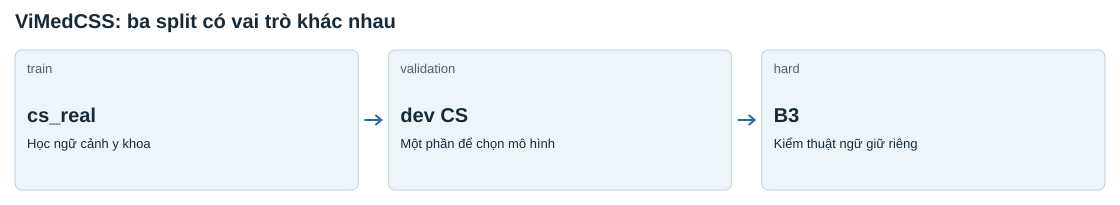

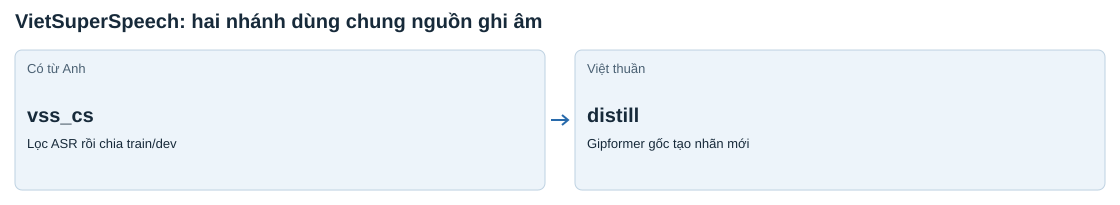

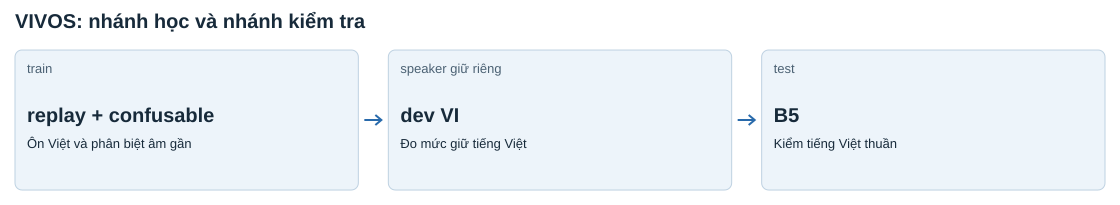

In [2]:
for title, nodes in [
    ('ViMedCSS: ba split có vai trò khác nhau', [
        ('train', 'cs_real', 'Học ngữ cảnh y khoa'),
        ('validation', 'dev CS', 'Một phần để chọn mô hình'),
        ('hard', 'B3', 'Kiểm thuật ngữ giữ riêng'),
    ]),
    ('VietSuperSpeech: hai nhánh dùng chung nguồn ghi âm', [
        ('Có từ Anh', 'vss_cs', 'Lọc ASR rồi chia train/dev'),
        ('Việt thuần', 'distill', 'Gipformer gốc tạo nhãn mới'),
    ]),
    ('VIVOS: nhánh học và nhánh kiểm tra', [
        ('train', 'replay + confusable', 'Ôn Việt và phân biệt âm gần'),
        ('speaker giữ riêng', 'dev VI', 'Đo mức giữ tiếng Việt'),
        ('test', 'B5', 'Kiểm tiếng Việt thuần'),
    ]),
]:
    flow(title, nodes)

## 3. Từ nguồn đến pool train: còn bao nhiêu dữ liệu?

Đọc mỗi sơ đồ từ trái sang phải. “Nguồn vào nhánh” đã là bản cục bộ sau converter hoặc chọn ứng viên;
không phải toàn bộ dữ liệu công bố trên Hub. Số giờ theo manifest hiện có, chưa gộp audio trùng.

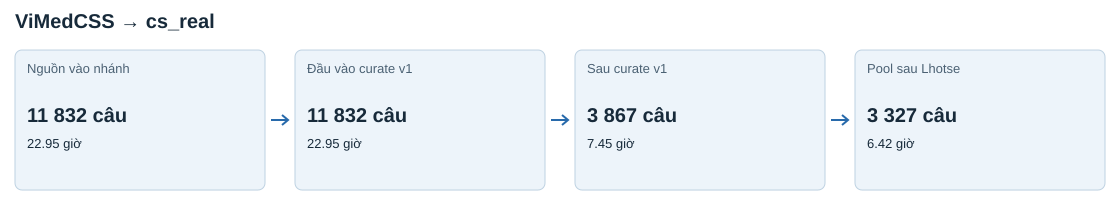

Đổi đường dẫn audio thành tuyệt đối; giữ nguyên các dòng train nguồn.


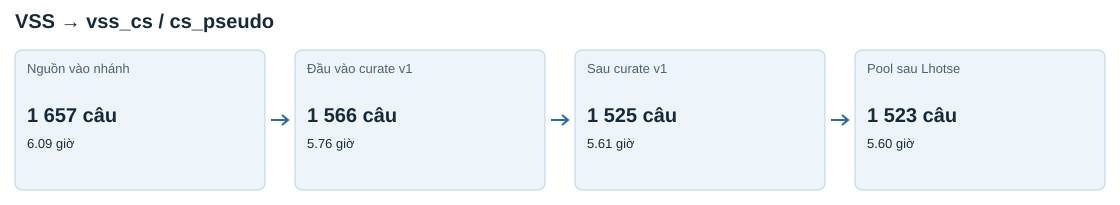

Tách theo video/speaker, seed 0; 91 câu sang dev, phần còn lại vào train.


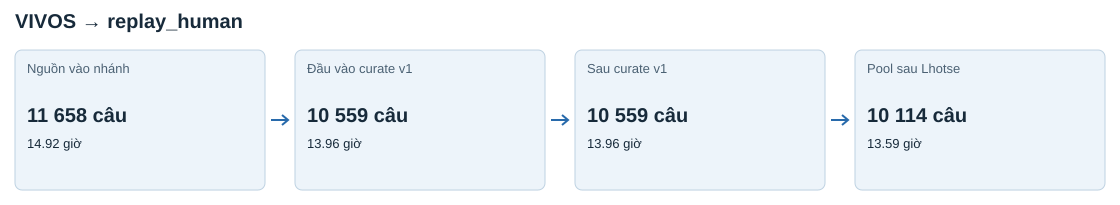

Tách theo speaker, seed 0; 4 speaker, 1 099 câu sang dev VI.


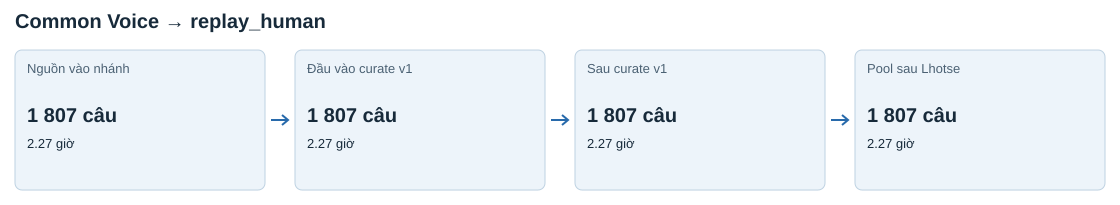

Dùng manifest train Việt thuần; không tách dev mới.


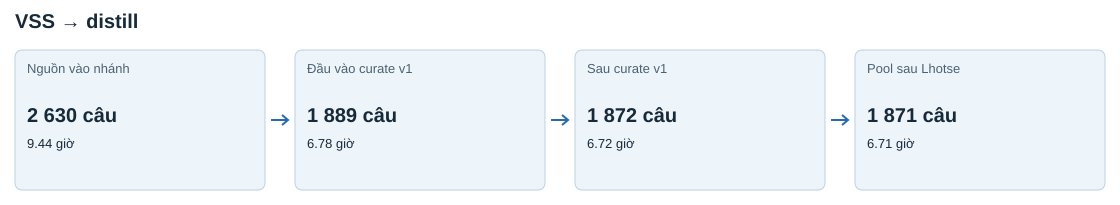

Gipformer gốc tạo đáp án: greedy phải trùng modified beam; giữ tốc độ 1–6 từ/giây.


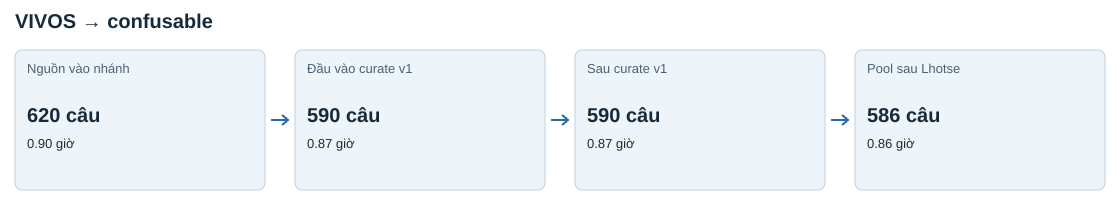

Chọn câu theo âm dễ nhầm; bỏ speaker thuộc dev VI. Không tạo audio tổng hợp.


Giai đoạn chung,Số câu,Giờ
Đầu vào curate v1,28 243,52.59
Curate v1 · trước Lhotse,20 220,36.88
Pool train v1 · sau Lhotse,19 228,35.46
Curate v1b · trước Lhotse,21 549,39.46


In [3]:
train_branches = defaultdict(list)
for row in lineage['stages']:
    if row['stage'] in ['Nguồn vào nhánh', 'Đầu vào curate v1', 'Sau curate v1', 'Pool sau Lhotse']:
        train_branches[row['branch']].append(row)
for branch, stages in train_branches.items():
    flow(branch, [(row['stage'], fmt(row['rows']) + ' câu', fmt(row['hours'], 2) + ' giờ') for row in stages])
    print(stages[1]['method'])

table(['Giai đoạn chung', 'Số câu', 'Giờ'], [
    [views[key]['label'], fmt(views[key]['rows']), fmt(views[key]['hours'], 2)]
    for key in ['train_input', 'train_v1', 'train_pool', 'train_v1b']
])

### Đọc kết quả

Nhánh VIVOS/confusable có thể dùng lại cùng WAV với replay, nên cộng các nhánh chỉ cho biết số dòng học.
Bản v1b là biến thể curate khác của cùng đầu vào, chưa được thay cho pool v1 khi phân tích ở đây.
Bước Lhotse còn lọc sau curate; vì vậy số câu trong `train_curated.jsonl` lớn hơn pool train thực tế.

## 4. Phương pháp xử lý đã dùng

### 4.1. Chuẩn hoá thành manifest và gắn tag

Converter thống nhất trường `id`, `audio`, `duration`, `text_tagged`, `dataset`, `source`, `speaker`, `split`.
ViMedCSS giữ hai cách gắn nhãn: `text_tagged_orig` bám danh sách thuật ngữ nguồn;
`text_tagged` áp thêm quy ước của dự án về từ mượn, catalog và luật nhận diện.

Ví dụ dưới chỉ minh hoạ biến đổi text, không phải transcript đã nghe xác nhận của một clip cụ thể.

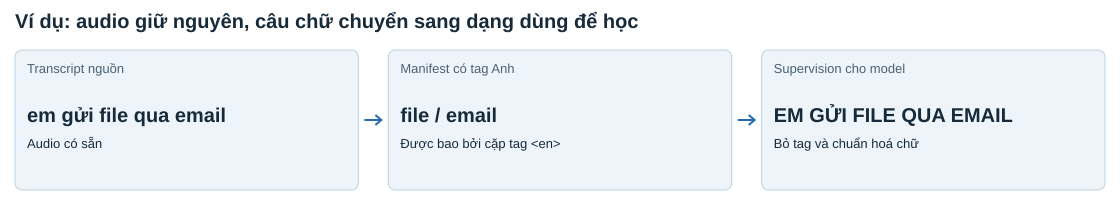

Dạng,Text minh hoạ
Nguồn,em gửi file qua email
Manifest,em gửi <en>file</en> qua <en>email</en>
Supervision,EM GỬI FILE QUA EMAIL


In [4]:
flow('Ví dụ: audio giữ nguyên, câu chữ chuyển sang dạng dùng để học', [
    ('Transcript nguồn', 'em gửi file qua email', 'Audio có sẵn'),
    ('Manifest có tag Anh', 'file / email', 'Được bao bởi cặp tag <en>'),
    ('Supervision cho model', 'EM GỬI FILE QUA EMAIL', 'Bỏ tag và chuẩn hoá chữ'),
])
table(['Dạng', 'Text minh hoạ'], [
    ['Nguồn', 'em gửi file qua email'],
    ['Manifest', 'em gửi <en>file</en> qua <en>email</en>'],
    ['Supervision', 'EM GỬI FILE QUA EMAIL'],
])

### 4.2. Lọc vss_cs: lọc rẻ trước, kiểm bằng ASR sau

Lọc rẻ dùng metadata và text để bớt tốn GPU: độ dài 1–20 giây, tỉ lệ token Anh ≤ 50%,
chặn rò rỉ, hạn chế câu có thuật ngữ chỉ xuất hiện một lần và trần 50 câu/thuật ngữ.

Tiếp theo, Qwen3-ASR-0.6B kiểm trước; faster-whisper large-v3 int8 chạy cho câu còn span chưa xác nhận.
Mỗi span cần ít nhất một ASR xác nhận, tất cả span trong câu phải đạt; WER phần Việt thấp nhất
trong các ASR có hyp phải ≤ 0.15. Giữ nhãn hiện có, không tự đổi sang toàn câu của ASR thầy.
Đây không phải quy tắc cả hai ASR phải đồng ý mọi câu.

Bước lọc rẻ,Câu còn,Giờ còn
vss_cs_candidates,31 949,117.32
độ dài 1–20 s,31 949,117.32
--max-en-frac 0.5,20 228,74.41
rò rỉ B1–B3 + reserved_b3,20 228,74.41
bỏ câu chỉ có thuật ngữ 1 lần (giữ 10%),17 249,63.48
--term-cap 50,12 351,45.49


Phạm vi ASR,Số câu
"Đã có hyp, được xét",6 412
Được giữ,1 657
Chưa có hyp tầng 1,5 939


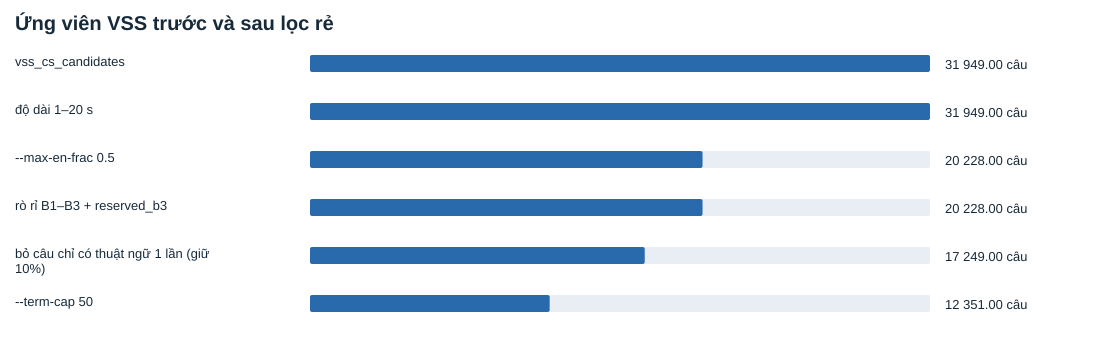

In [5]:
table(['Bước lọc rẻ', 'Câu còn', 'Giờ còn'], [
    [row['step'], fmt(row['rows']), fmt(row['hours'], 2)] for row in lineage['vss_prefilter_steps']
])
agreement = lineage['agreement']
table(['Phạm vi ASR', 'Số câu'], [
    ['Đã có hyp, được xét', fmt(agreement['examined'])],
    ['Được giữ', fmt(agreement['kept'])],
    ['Chưa có hyp tầng 1', fmt(agreement['without_first_teacher_hyp'])],
])
bars('Ứng viên VSS trước và sau lọc rẻ', [(row['step'], row['rows']) for row in lineage['vss_prefilter_steps']], ' câu')

**Cần hiểu đúng mẫu số:** log ghi giữ 1.657/6.412 câu đã có hyp được xét; còn 5.939 ứng viên chưa có
hyp tầng 1. Không coi 1.657/12.351 là tỉ lệ đạt của một lượt ASR đã kiểm hết toàn bộ ứng viên.

Đối chiếu [log lọc ASR](../../data/raw/vss_full/vss_cs_clean.jsonl.report.md),
[mã chạy hai tầng](../../tools/vss_cs_run.py) và [mã lọc](../../tools/agreement_filter.py).

### 4.3. Tách dev, tạo distill và confusable

- VSS chia theo video/speaker, seed 0: 1.566 train và 91 dev.
- VIVOS chia theo speaker: 10.559 train và 1.099 dev VI thuộc 4 speaker; confusable bỏ các speaker dev này.
- ViMedCSS validation xáo seed 0, lấy 600 rồi bỏ 1 câu dưới 0.5 giây; ghép 599 với 91 VSS thành 690 câu dev CS.
  Cách này vẫn còn nguồn ViMedCSS chung với train.
- Distill chọn VSS Việt thuần, loại ID ứng viên CS và video thuộc nhánh CS, giữ 1–20 giây.
  Từ pool 2.630 câu/9.44 giờ, Gipformer gốc giải mã greedy và modified beam;
  giữ hai câu chữ giống nhau và 1–6 từ/giây, còn 1.889 câu/6.78 giờ trước curate.
- Confusable chọn câu VIVOS có âm Việt dễ nhầm sang Anh, ví dụ “tim/team”. Audio có sẵn và nhãn vẫn là tiếng Việt.

Mã: [prep_e3_v1.py](../../ft/prep_e3_v1.py), [make_distill.py](../../ft/make_distill.py),
[make_confusables.py](../../tools/make_confusables.py).

### 4.4. Curate, Lhotse và tăng cường

Curate gộp sáu manifest, chặn test_only, giữ finance ngoài train, giới hạn 50 câu/thuật ngữ,
2% giờ/người nói và 35% giờ CS/domain, miễn `other`. Log v1 ghi trần synthetic 20%,
nhưng không có TTS nên bước đó không loại câu. Tham số lịch sử lấy từ log;
code/config hiện tại có thể đã đổi giá trị mặc định.

In [6]:
table(['Bước curate v1', 'Câu còn', 'Giờ còn'], [
    [row['step'], fmt(row['rows']), fmt(row['hours'], 2)] for row in lineage['curate_steps']
])
print('Lhotse lọc thêm:', fmt(data['lhotse']['removed_from_curated']), 'câu /',
      fmt(data['lhotse']['removed_hours'], 2), 'giờ từ curate v1.')

Bước curate v1,Câu còn,Giờ còn
đầu vào,28 243,52.59
chặn dữ liệu test_only,28 243,52.59
--holdout-domain finance,28 198,52.42
--max-per-term 50,27 715,51.45
--max-speaker-share 0.02,27 715,51.45
--max-domain-share 0.35,20 220,36.88
--max-synthetic-share 0.2,20 220,36.88


Lhotse lọc thêm: 992 câu / 1.42 giờ từ curate v1.


Lhotse loại speaker/source/text trùng bench, thuật ngữ reserved_b3, câu ngoài 1–20 giây,
text rỗng hoặc audio không đọc được. Text chuẩn hoá, bỏ tag, đổi IN HOA; audio về 16 kHz.
Lần chạy đặt mô phỏng điện thoại 8 kHz cho khoảng 30% cut và thêm tốc độ 0.9/1.1.

Mã và log: [curate](../../data/e3_v1/train_curated.jsonl.report.md),
[to_lhotse.py](../../ft/to_lhotse.py), [run_e3_v1.sh](../../ft/run_e3_v1.sh).

## 5. Tổng quan các tập đang dùng

“Giờ gộp hash” giữ một thời lượng lớn nhất cho mỗi nhóm file có SHA256 giống nhau.
Nó giúp thấy lặp byte; các bản cắt/nén khác byte vẫn có thể chứa nội dung nói trùng.
“Mã/cụm nói” dùng `speaker_cluster` nếu có, nếu không dùng `speaker`; mã video không bảo đảm là người riêng biệt.

Tập,Câu,Giờ theo dòng,Giờ gộp hash,Câu có Anh,Giờ câu có Anh,Mã/cụm nói
Pool train v1 · sau Lhotse,19 228,35.46,34.59,2 840,8.14,1 764
Curate v1 · trước Lhotse,20 220,36.88,35.98,3 087,8.60,1 953
Curate v1b · trước Lhotse,21 549,39.46,38.56,4 416,11.19,2 217
Dev chen Anh,690,1.49,1.49,583,1.27,512
Dev tiếng Việt,1 099,0.96,0.96,0,0.00,4
Bench v0-draft,4 238,5.19,5.19,2 072,2.82,614
Dev CS · cuts cho loss,601,1.32,1.32,505,1.13,440
Dev Việt · cuts cho loss,1 031,0.91,0.91,0,0.00,4


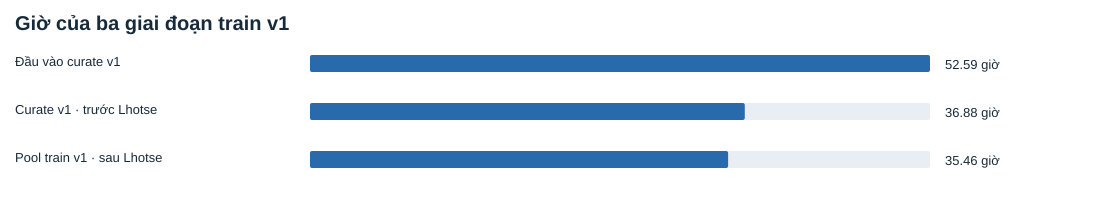

In [7]:
overview_keys = ['train_pool', 'train_v1', 'train_v1b', 'dev_cs', 'dev_vi', 'bench', 'dev_cs_pool', 'dev_vi_pool']
table(['Tập', 'Câu', 'Giờ theo dòng', 'Giờ gộp hash', 'Câu có Anh', 'Giờ câu có Anh', 'Mã/cụm nói'], [
    [views[key]['label'], fmt(views[key]['rows']), fmt(views[key]['hours'], 2),
     fmt(views[key]['audio']['unique_content_hours'], 2), fmt(views[key]['cs_rows']),
     fmt(views[key]['cs_hours'], 2), fmt(views[key]['speaker_units'])] for key in overview_keys
])
bars('Giờ của ba giai đoạn train v1', [(views[key]['label'], views[key]['hours']) for key in ['train_input', 'train_v1', 'train_pool']], ' giờ')

## 6. Khám phá một tập bằng biểu đồ

Đổi `VIEW_KEY` trong ô tiếp theo rồi chạy lại để xem một trong 13 tập.
Mặc định là pool train thực tế sau Lhotse. Các biểu đồ hiển thị nguồn, độ dài, lĩnh vực,
từ Anh và metadata; không cần chạy lại ASR.

Khoảng thời lượng trái đóng, phải mở: 2–4 gồm 2 giây và nhỏ hơn 4 giây.
Khoảng 20–30 có thể chứa câu đúng 20 giây, không tự chứng minh câu vượt giới hạn 20 giây.

Đang xem: Pool train v1 · sau Lhotse
Các lựa chọn: train_v1, train_v1b, dev_cs, dev_vi, bench, train_input, bench_B1, bench_B2, bench_B3, bench_B5, dev_cs_pool, dev_vi_pool, train_pool


Chỉ số,Giá trị
Câu,19 228
Giờ theo dòng,35.46
Câu có Anh,2 840
Thuật ngữ Anh khác nhau,1 433
Trung vị độ dài (giây),5.19
90% câu ngắn hơn (giây),13.29
Số span Anh,4 010


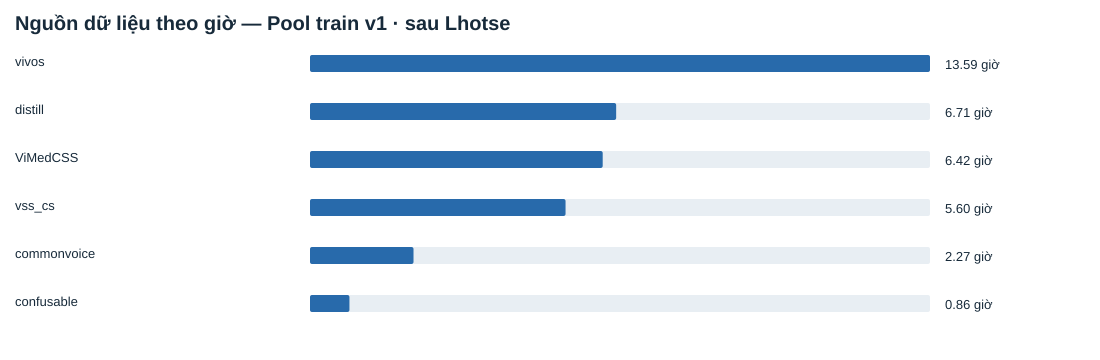

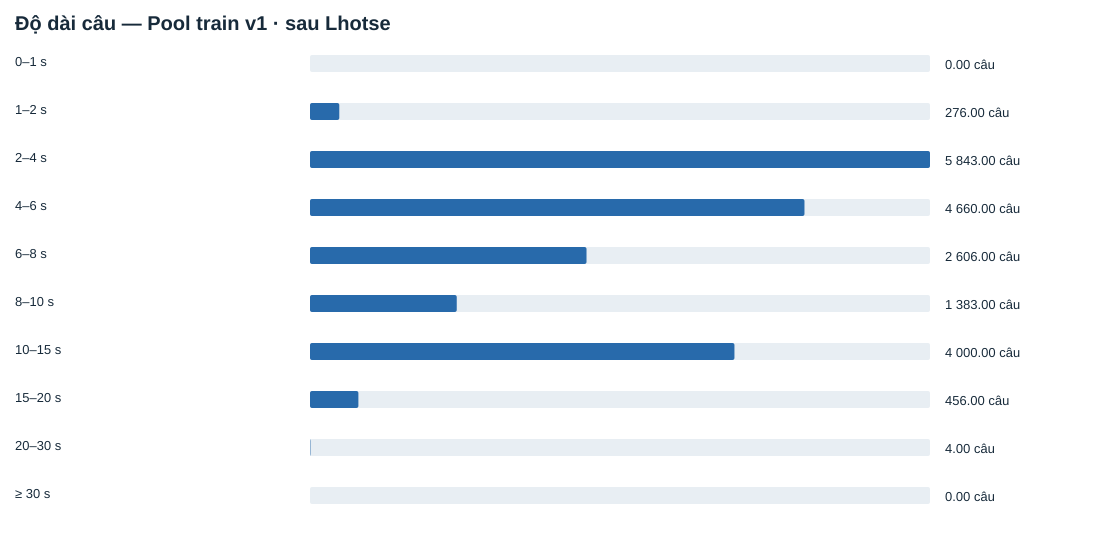

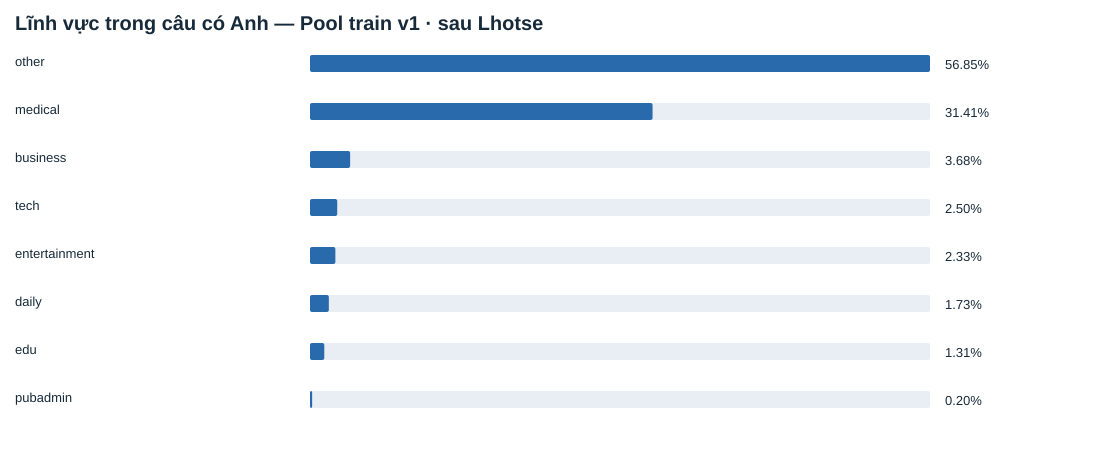

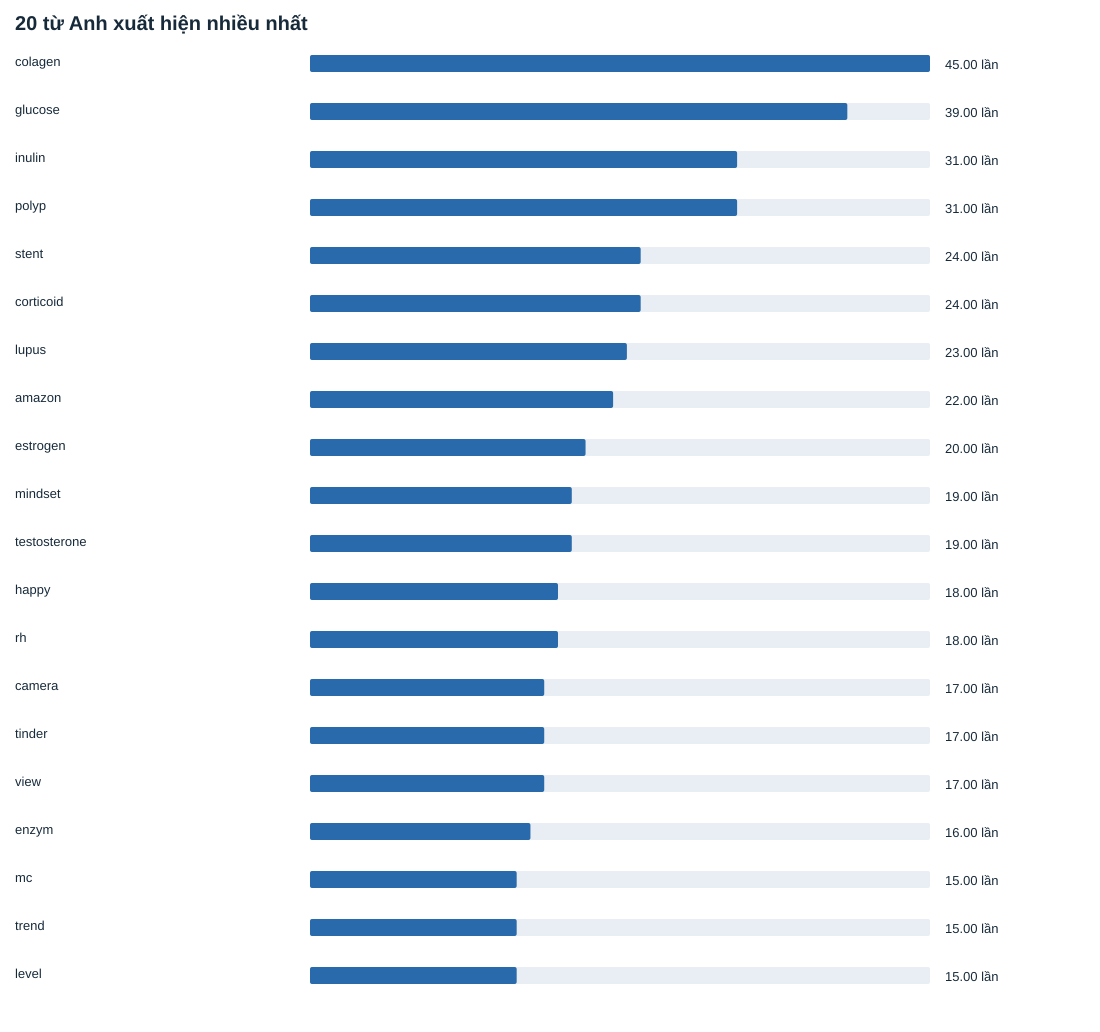

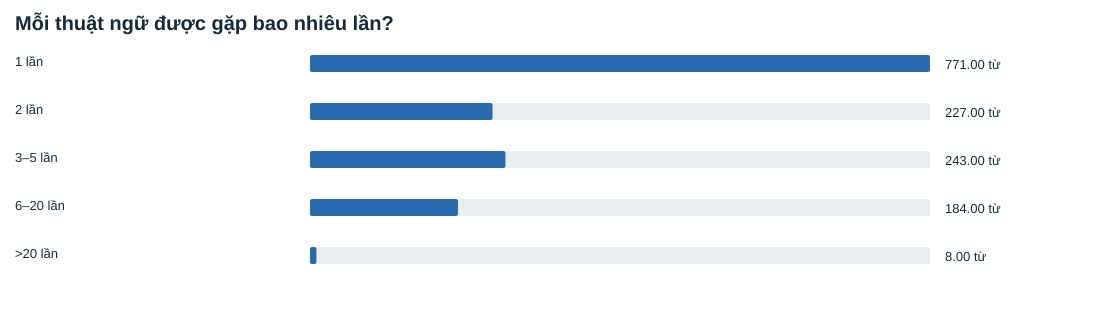

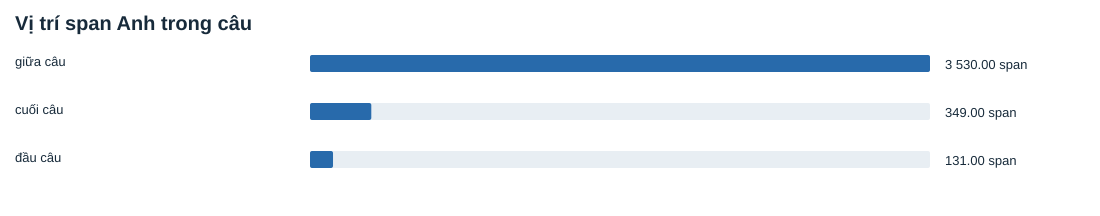

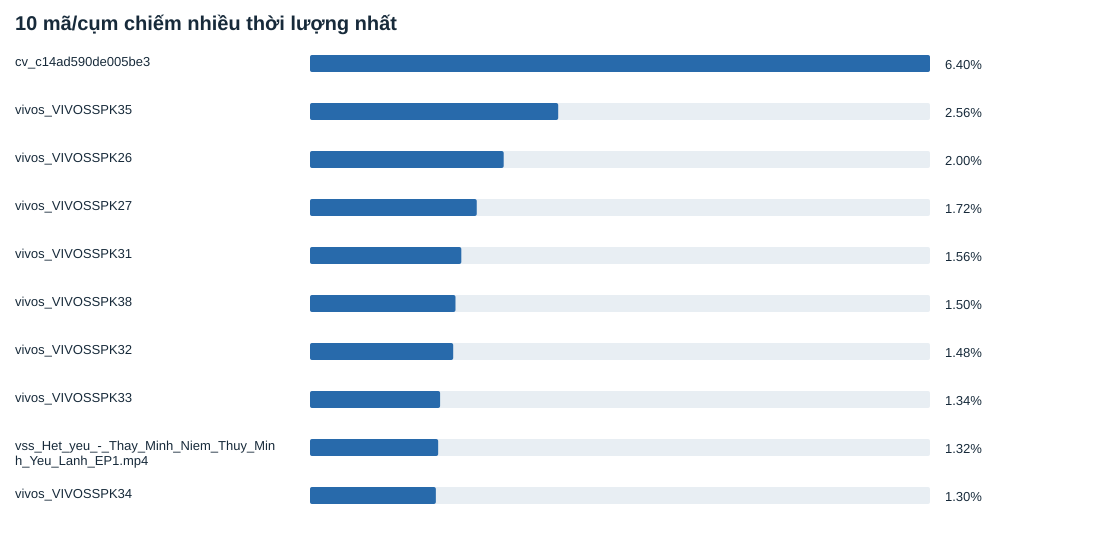

Metadata,Phân bố theo số câu
region,unk: 19 228
gender,u: 19 228
channel,wideband: 19 228
label_source,unknown: 15 834; distill:gipformer1.5-68M-rnnt: 1 871; pseudo:Zipformer-30M-RNNT-6000h: 1 523


In [8]:
VIEW_KEY = 'train_pool'
if VIEW_KEY not in views:
    raise ValueError(f'Chọn một trong: {list(views)}')
selected = views[VIEW_KEY]
print('Đang xem:', selected['label'])
print('Các lựa chọn:', ', '.join(views))
table(['Chỉ số', 'Giá trị'], [
    ['Câu', fmt(selected['rows'])], ['Giờ theo dòng', fmt(selected['hours'], 2)],
    ['Câu có Anh', fmt(selected['cs_rows'])], ['Thuật ngữ Anh khác nhau', fmt(selected['distinct_terms'])],
    ['Trung vị độ dài (giây)', fmt(selected['duration']['median'], 2)],
    ['90% câu ngắn hơn (giây)', fmt(selected['duration']['p90'], 2)],
    ['Số span Anh', fmt(selected['spans'])],
])
bars('Nguồn dữ liệu theo giờ — ' + selected['label'], [(r['value'], r['hours']) for r in selected['datasets']], ' giờ')
bars('Độ dài câu — ' + selected['label'], [(r['label'], r['count']) for r in selected['duration_bins']], ' câu')
bars('Lĩnh vực trong câu có Anh — ' + selected['label'], [(r['value'], r['hours_pct']) for r in selected['cs_domains']], '%')
bars('20 từ Anh xuất hiện nhiều nhất', [(r['term'], r['occurrences']) for r in selected['terms'][:20]], ' lần')
bars('Mỗi thuật ngữ được gặp bao nhiêu lần?', [(r['label'], r['count']) for r in selected['term_buckets']], ' từ')
bars('Vị trí span Anh trong câu', selected['span_position'].items(), ' span')
bars('10 mã/cụm chiếm nhiều thời lượng nhất', [(r['unit'], r['pct']) for r in selected['top_speakers']], '%')
table(['Metadata', 'Phân bố theo số câu'], [
    [field, '; '.join(f"{r['value']}: {fmt(r['rows'])}" for r in selected[field])]
    for field in ['region', 'gender', 'channel', 'label_source']
])

**Diễn giải:** nhiều từ chỉ được gặp rất ít lần sẽ khó học ổn định. Thời lượng theo mã/video chỉ là
một chỉ báo tập trung dữ liệu. `label_source=unknown` nghĩa là trường metadata thiếu;
cần kết hợp phần nguồn ở mục 2, không suy ra rằng mọi câu này không rõ dataset hay đều có nhãn người.

## 7. Train có cùng lĩnh vực với dev và bench không?

So sánh trong số giờ **toàn câu có tag Anh** của từng tập. Domain vss_cs được suy từ từ khoá,
nhiều câu còn là `other`, nên đây là chỉ báo gần đúng về chủ đề.

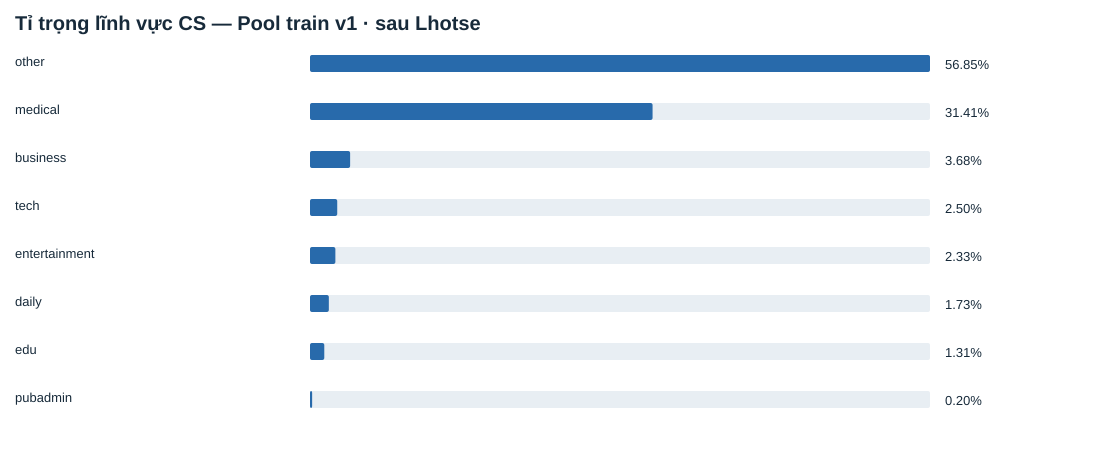

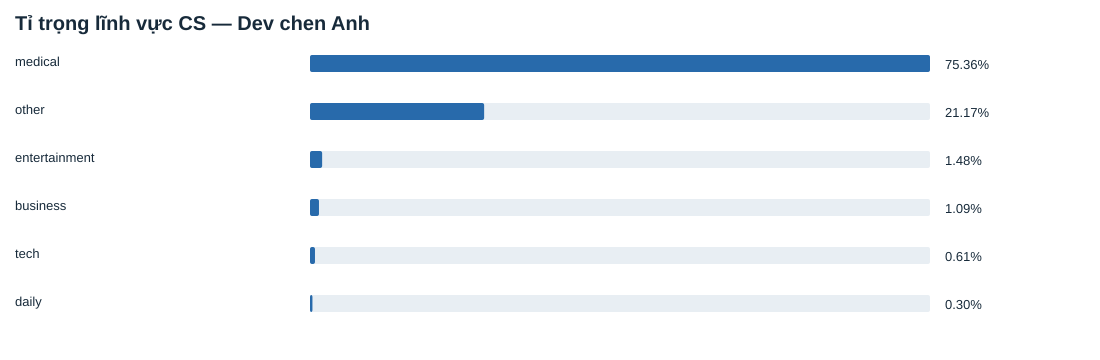

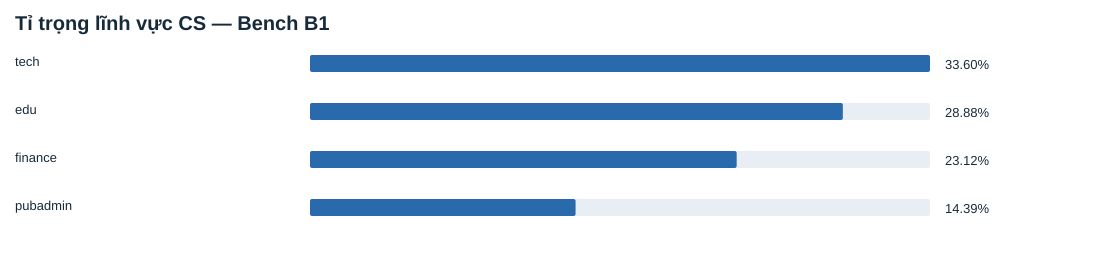

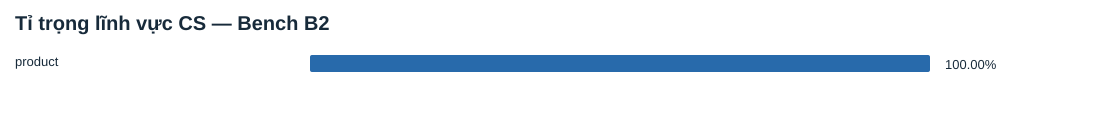

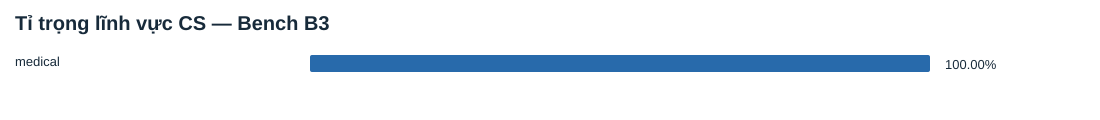

In [9]:
for key in ['train_pool', 'dev_cs', 'bench_B1', 'bench_B2', 'bench_B3']:
    bars('Tỉ trọng lĩnh vực CS — ' + views[key]['label'], [(r['value'], r['hours_pct']) for r in views[key]['cs_domains']], '%')

## 8. Bench được dựng từ nguồn nào?

G-Group → B1; consensus → B2; ViMedCSS hard → B3; Việt thuần của VIVOS test/G-Group/consensus → B5.
Common Voice test có manifest trên máy nhưng không nằm trong bench hiện tại.

[Log build](../../data/bench_v0_draft/build.log) dùng `--accept all` cho các ứng viên đủ điều kiện;
bench còn là bản nháp, không đồng nghĩa mọi câu và tag đã được người nghe duyệt.
ViMedCSS hard có 658 ứng viên; bỏ 134 câu không còn tag Anh theo nhãn Spec, còn 524 câu B3.

Nguồn gốc,Split bench,Câu,Giờ
ZAC / consensus · bộ cục bộ,B2,218,0.40
ZAC / consensus · bộ cục bộ,B5,1 081,1.36
G-Group · bốn bộ vi-asr test,B1,1 330,1.38
G-Group · bốn bộ vi-asr test,B5,325,0.27
ViMedCSS,B3,524,1.04
VIVOS,B5,760,0.75


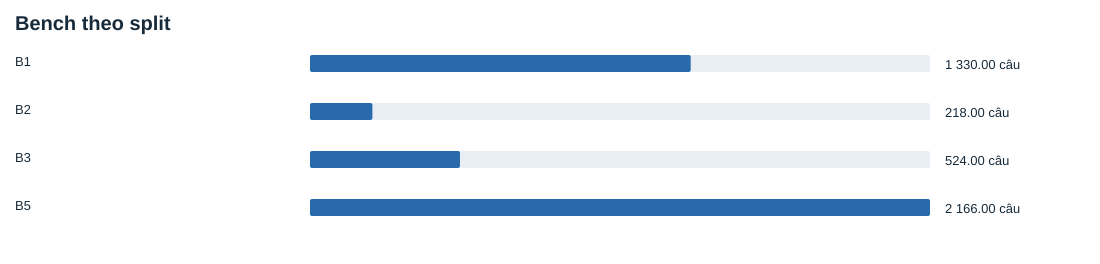

In [10]:
source_names = {r['key']: r['name'] for r in lineage['sources']}
table(['Nguồn gốc', 'Split bench', 'Câu', 'Giờ'], [
    [source_names[r['origin']], r['split'], fmt(r['rows']), fmt(r['hours'], 2)] for r in lineage['bench_composition']
])
bars('Bench theo split', [(split, views['bench_' + split]['rows']) for split in ['B1', 'B2', 'B3', 'B5']], ' câu')

## 9. Từ Anh trong bench đã gặp trong train chưa?

Đếm theo **lượt xuất hiện span trong bench**, không phải phần trăm câu.
`unseen`: chưa gặp trong train; `synth_only`: chỉ có ở nhánh tổng hợp;
`real_1-4` / `real_5+`: gặp 1–4 / ít nhất 5 lần trong các dòng không gắn synthetic.
“real” ở đây vẫn có thể dùng nhãn máy; không đồng nghĩa nhãn người.

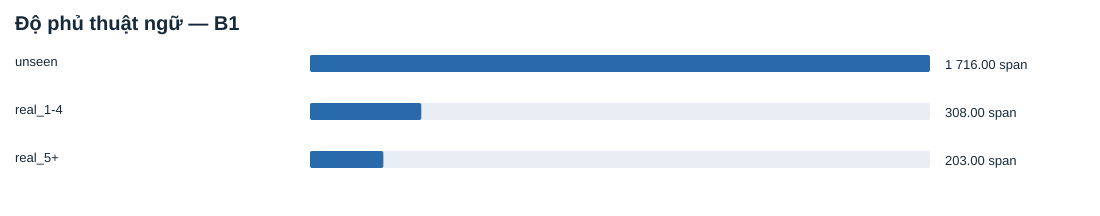

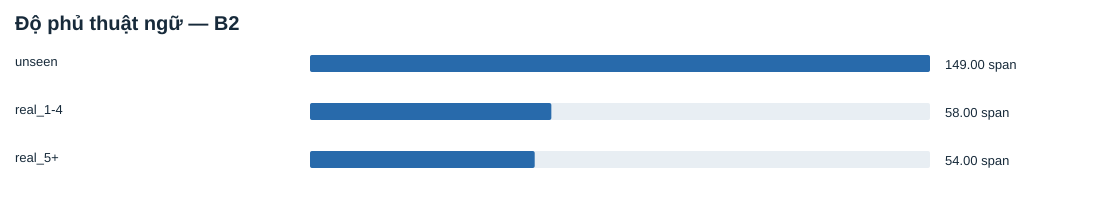

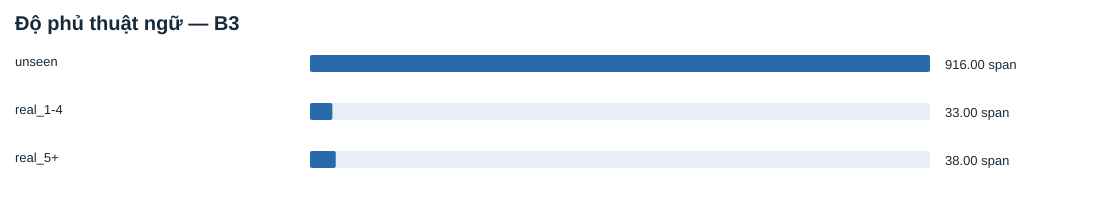

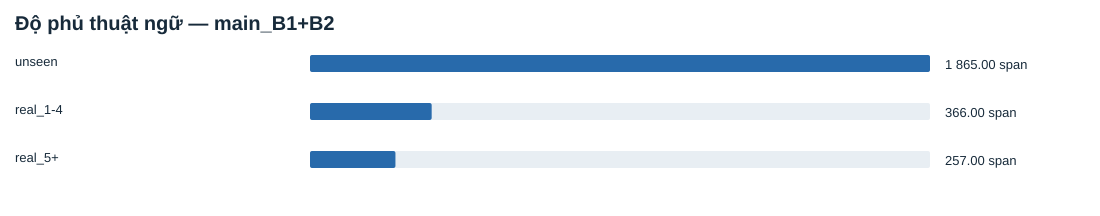

Bench,Tổng span,Từ khác nhau,Span chưa gặp,% span chưa gặp
B1,2 227,1 521,1 716,77.05%
B2,261,135,149,57.09%
B3,987,582,916,92.81%
main_B1+B2,2 488,1 618,1 865,74.96%


Từ chưa gặp trong train,Lượt trong B1+B2
gov,24
website,19
zalo,14
ielts,13
visa,11
web,11
edu,11
token,10
api,8
vietcombank,7


Thuật ngữ B3 được giữ riêng: 315
Trong số đó đã xuất hiện trong pool train: 0


In [11]:
coverage_rows = []
for split in ['B1', 'B2', 'B3', 'main_B1+B2']:
    item = data['coverage']['train_pool/' + split]
    unseen = item['buckets'].get('unseen', 0)
    coverage_rows.append([split, fmt(item['spans']), fmt(item['terms']), fmt(unseen),
                          fmt(100 * unseen / item['spans'] if item['spans'] else 0, 2) + '%'])
    bars('Độ phủ thuật ngữ — ' + split, item['buckets'].items(), ' span')
table(['Bench', 'Tổng span', 'Từ khác nhau', 'Span chưa gặp', '% span chưa gặp'], coverage_rows)
main_coverage = data['coverage']['train_pool/main_B1+B2']
table(['Từ chưa gặp trong train', 'Lượt trong B1+B2'], [
    [r['term'], r['bench_occurrences']] for r in main_coverage['unseen_terms'][:25]
])
reserved = data['coverage']['train_pool/B3']
print('Thuật ngữ B3 được giữ riêng:', reserved['reserved_b3_terms'])
print('Trong số đó đã xuất hiện trong pool train:', len(reserved['reserved_b3_seen']))

B1+B2 có khoảng 75% lượt span thuộc từ chưa gặp trong pool train: đây là một giới hạn độ phủ đáng chú ý.
Riêng 315 thuật ngữ `reserved_b3` phải tiếp tục giữ ngoài train; không lấy chúng vào train chỉ để tăng điểm B3.
Các thuật ngữ thông thường khác xuất hiện trong câu B3 vẫn có thể đã được gặp ở train.

## 10. Trùng lặp và rò rỉ: cần phân biệt từng mức

Trùng source thường là cùng nguồn/video; trùng text có thể chỉ là cùng một câu phổ thông.
Trùng SHA256 nghĩa là file audio giống hệt byte. Các tiêu chí là những góc nhìn chồng lấp;
không cộng các cột thành tổng số câu rò rỉ.

So với pool train,Chung source,Chung mã/cụm,Cùng text,Cùng đường dẫn,Cùng byte audio
dev_cs,373,373,5,0,1
dev_vi,0,0,130,0,0
bench,0,0,0,0,0
dev_cs_pool,355,355,5,0,1
dev_vi_pool,0,0,130,0,0


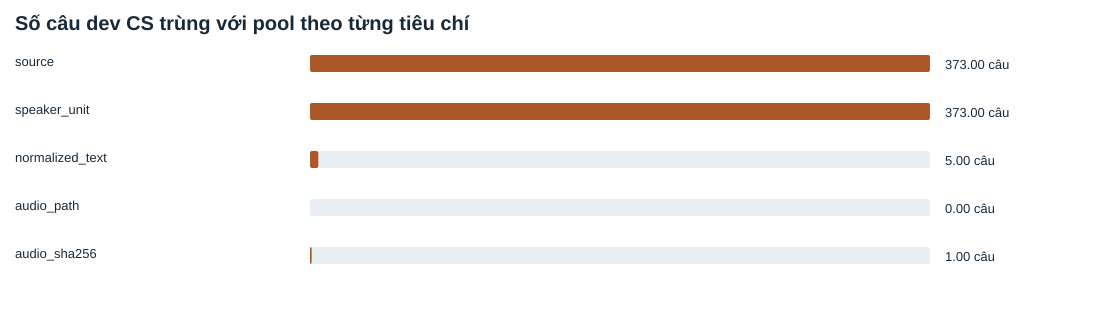

Pool train và bench: số câu chung source = 0 , cùng byte audio = 0


In [12]:
criteria = ['source', 'speaker_unit', 'normalized_text', 'audio_path', 'audio_sha256']
pool_overlaps = [r for r in data['overlaps'] if r['left'] == 'train_pool']
table(['So với pool train', 'Chung source', 'Chung mã/cụm', 'Cùng text', 'Cùng đường dẫn', 'Cùng byte audio'], [
    [r['right']] + [fmt(r[k]['right_rows']) for k in criteria] for r in pool_overlaps
])
dev_overlap = next(r for r in pool_overlaps if r['right'] == 'dev_cs')
bench_overlap = next(r for r in pool_overlaps if r['right'] == 'bench')
bars('Số câu dev CS trùng với pool theo từng tiêu chí', [(k, dev_overlap[k]['right_rows']) for k in criteria], ' câu', '#ad5728')
print('Pool train và bench: số câu chung source =', bench_overlap['source']['right_rows'],
      ', cùng byte audio =', bench_overlap['audio_sha256']['right_rows'])

**Kết quả cần chú ý:** 373/690 câu dev CS chung nguồn với pool train, trong đó có một WAV trùng byte.
WAV trùng này là file im lặng toàn bộ; vẫn cần loại/khôi phục audio đúng.
Pool sau Lhotse không còn trùng source/audio với bench theo các phép kiểm hiện có.
Manifest trước Lhotse có thể còn trùng bench, nên không dùng số trùng ở giai đoạn đó để kết luận pool cuối bị rò rỉ.

Dev VI có text lặp với train nhưng không có audio/source trùng theo phép kiểm; câu chữ phổ thông lặp lại
chưa đủ chứng minh cùng bản ghi âm. Dev CS để tính loss có 601 câu, còn dev giải mã để chọn checkpoint
có 690 câu; dev VI tương ứng 1.031 và 1.099. Các điểm đo này có phạm vi khác nhau.

## 11. Kiểm audio: file thiếu, im lặng và mẫu giải mã

Lần EDA đã kiểm file, SHA256, WAV header và quét PCM để tìm file im lặng số toàn bộ.
Mẫu giải mã phân tầng chọn tối đa 8 file cho mỗi nguồn/vai trò, seed 0;
FFmpeg/FFprobe giải mã tối đa 30 giây đầu mỗi file mẫu.

RMS/peak đo mức tín hiệu. Tỉ lệ khung yên là số khung 20 ms dưới −45 dBFS.
Không dùng các số này để gọi đó là SNR hoặc khẳng định nội dung transcript đúng.

In [13]:
table(['Tập', 'Dòng WAV im lặng toàn bộ', 'Dòng WAV 0 frame', 'Dòng thiếu file', 'Dòng audio byte lặp dư'], [
    [views[key]['label'], views[key]['audio'].get('digital_silence_rows', 0),
     views[key]['audio'].get('zero_frame_rows', 0), views[key]['audio'].get('missing_rows', 0),
     views[key]['audio'].get('duplicate_content_excess', 0)]
    for key in ['train_v1', 'train_v1b', 'train_pool', 'dev_cs', 'dev_vi', 'bench']
])
issues = read_csv('audit_issues.csv')
pool_rows = read_csv('training_pool_rows.csv')
exposure = {r['id']: int(r['uses_in_mix']) for r in read_csv('mix_exposure.csv')}
silent_ids = {r['id'] for r in issues if r['view'] == 'train_pool' and r['issue'] == 'wav_all_digital_silence'}
table(['ID im lặng trong pool', 'Nhóm', 'Giây', 'Lượt trong file trộn'], [
    [r['id'], r['group'], fmt(float(r['duration']), 2), exposure[r['id']]]
    for r in pool_rows if r['id'] in silent_ids
])
sample_groups = defaultdict(list)
for row in data['audio_sample']:
    sample_groups[row['dataset']].append(row)
sample_rows = []
for source, rows in sorted(sample_groups.items()):
    good = [r for r in rows if not r.get('error')]
    sample_rows.append([source, len(rows), len(good),
                        fmt(statistics.median(r['rms_dbfs'] for r in good), 2) if good else '—',
                        fmt(statistics.mean(r['quiet_frame_pct_minus45dbfs'] for r in good), 2) if good else '—'])
table(['Nguồn', 'File mẫu', 'Giải mã được', 'RMS trung vị dBFS', 'Khung yên TB %'], sample_rows)

Tập,Dòng WAV im lặng toàn bộ,Dòng WAV 0 frame,Dòng thiếu file,Dòng audio byte lặp dư
Curate v1 · trước Lhotse,9,10,0,616
Curate v1b · trước Lhotse,13,10,0,622
Pool train v1 · sau Lhotse,9,0,0,593
Dev chen Anh,1,0,0,0
Dev tiếng Việt,0,0,0,0
Bench v0-draft,0,0,0,0


ID im lặng trong pool,Nhóm,Giây,Lượt trong file trộn
vmc_Med_CS-3077-11,cs_real,7.00,55
vmc_Med_CS-3858-12,cs_real,4.00,55
vmc_Med_CS-3858-9,cs_real,6.00,55
vmc_Med_CS-4770-1,cs_real,9.00,56
vmc_Med_CS-4952-3,cs_real,3.00,55
vmc_Med_CS-4952-4,cs_real,4.00,54
vmc_Med_CS-4962-1,cs_real,5.00,55
vmc_Med_CS-5043-12,cs_real,10.00,54
vmc_Med_CS-64_1-4,cs_real,8.00,54


Nguồn,File mẫu,Giải mã được,RMS trung vị dBFS,Khung yên TB %
ViMedCSS,24,24,-21.23,12.47
commonvoice,8,8,-26.33,52.52
confusable,8,8,-20.81,21.05
consensus,16,16,-26.01,27.66
distill,8,8,-21.05,7.04
vi-asr-edu-test,8,8,-21.96,12.00
vi-asr-finance-test,8,8,-21.05,16.92
vi-asr-pubadmin-test,16,16,-18.49,14.62
vi-asr-tech-test,8,8,-19.17,16.58
vivos,24,24,-23.50,32.17


Pool vẫn còn 9 dòng WAV im lặng toàn bộ. Hai file im lặng có thể cho cùng SHA256 dù không phải
cùng nội dung lời nói; đối chiếu cả nhãn, PCM và ID thay vì chỉ đọc số trùng hash.
Một nhóm hash trong pool có nhãn khác nhau cũng là WAV im lặng, cần xử lý trước khi train tiếp.
Các file mẫu giải mã được không chứng minh toàn bộ corpus đều sạch.

## 12. Tăng cường và lấy lặp: vì sao có gần 960 giờ?

“Cut” có thể là một bản tốc độ hoặc một lần lấy lặp của cùng câu.
File mix đã chuẩn bị khoảng 960 giờ từ 19.228 câu gốc; đây là giờ kế hoạch sau lấy lặp và tăng cường,
không phải 960 giờ ghi âm độc lập và không xác nhận mô hình đã học hết file.

Nhóm,Câu gốc,Cut trong file mix,Giờ trong mix,Lượt TB/câu gốc
confusable,586,34 029,50.53,58.07
cs_pseudo,1 523,27 288,101.07,17.92
cs_real,3 327,182 171,353.69,54.76
distill,1 871,55 958,202.11,29.91
replay_human,11 921,188 519,252.64,15.81


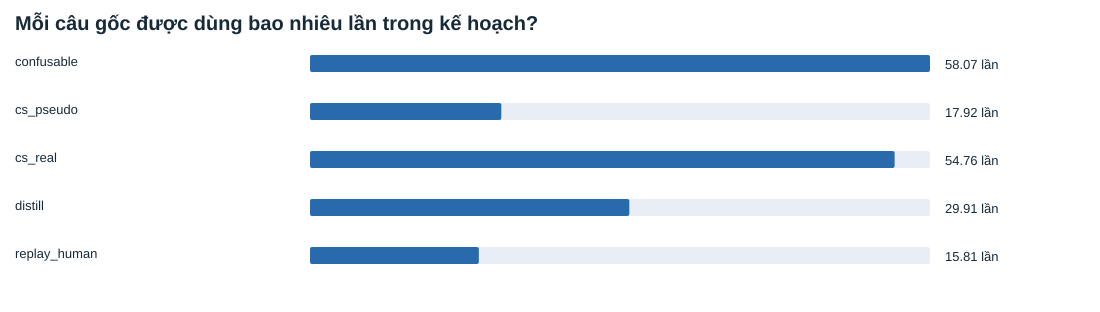

Tổng cut: 487 965 | Giờ: 960.04 | Câu gốc đã dùng: 19 228


In [14]:
mix = data['lhotse']['mix_exposure']
table(['Nhóm', 'Câu gốc', 'Cut trong file mix', 'Giờ trong mix', 'Lượt TB/câu gốc'], [
    [r['group'], fmt(r['base_rows']), fmt(r['cuts_in_mix']), fmt(r['hours_in_mix'], 2), fmt(r['mean_uses_per_original'], 2)]
    for r in mix['groups']
])
bars('Mỗi câu gốc được dùng bao nhiêu lần trong kế hoạch?', [(r['group'], r['mean_uses_per_original']) for r in mix['groups']], ' lần')
print('Tổng cut:', fmt(mix['cuts']), '| Giờ:', fmt(mix['hours'], 2), '| Câu gốc đã dùng:', fmt(mix['base_rows_used']))

## 13. Giới hạn và hướng xử lý

1. **Xử lý audio lỗi trước.** Nghe/kiểm lại 9 WAV im lặng trong pool và file dev trùng, lấy lại audio đúng hoặc loại.
2. **Tách dev theo nguồn.** Chọn lại manifest dev không chung nguồn/video với train; báo riêng y khoa và hội thoại.
3. **Bổ sung đúng phần thiếu.** Tìm câu thật chất lượng tốt ở lĩnh vực mục tiêu, tăng ngữ cảnh và độ phủ từ B1/B2;
   tiếp tục giữ riêng `reserved_b3` và dữ liệu test_only.
4. **Kiểm nhãn bench.** Nghe duyệt câu và tag còn nháp trước khi dùng để kết luận mô hình tốt hơn.
5. **Bổ sung metadata.** Region/gender/viet_level phần lớn chưa có; mã video/cụm chỉ là đại diện,
   nên chưa thể kết luận mô hình tốt cho mọi giọng hay nhóm người.
6. **Ghi snapshot cho lần chạy mới.** Lưu revision dataset gốc, hash manifest, tham số và log.

Độ phủ thiếu, lệch miền và dev chung nguồn là những dấu hiệu cần kiểm tiếp;
EDA chưa chứng minh riêng yếu tố nào là nguyên nhân duy nhất khiến điểm mô hình thay đổi.

## 14. Truy xuất nguồn và kiểm tính nhất quán

URL upstream xác định tên dataset. Repo chưa có immutable Hub revision/checksum gói gốc cho mọi nguồn,
nên chưa bảo đảm tải lại đúng từng byte chỉ từ URL. Hash cục bộ xác định bản đã phân tích.
Hash code/config là trạng thái khi bổ sung phần nguồn; tham số lịch sử phải đối chiếu log lần chạy.

File để xem thêm: [nguồn và xử lý JSON](source_provenance.json), [các giai đoạn CSV](dataset_lineage.csv),
[hash bằng chứng CSV](lineage_evidence.csv), [câu trong pool](training_pool_rows.csv),
[dòng bị lọc sau curate](curated_rows_not_in_train_pool.csv), [thuật ngữ](term_frequency.csv),
[trùng lặp](overlap.csv), [audio mẫu](audio_sample.csv), [vấn đề audit](audit_issues.csv).

In [15]:
# Check relationships without rerunning the audio scan.
for stage, key in [('Đầu vào curate v1', 'train_input'), ('Sau curate v1', 'train_v1'), ('Pool sau Lhotse', 'train_pool')]:
    assert sum(r['rows'] for r in lineage['stages'] if r['stage'] == stage) == views[key]['rows'], stage
assert sum(r['rows'] for r in lineage['bench_composition']) == views['bench']['rows']
assert len(pool_rows) == views['train_pool']['rows']
assert agreement['examined'] + agreement['without_first_teacher_hyp'] == lineage['vss_prefilter_steps'][-1]['rows']
print('Số dòng của các nhánh, pool, bench và phạm vi ASR nhất quán với snapshot.')

table(['File bằng chứng', 'SHA256 snapshot'], [[r['path'], r['sha256']] for r in lineage['evidence']])

Số dòng của các nhánh, pool, bench và phạm vi ASR nhất quán với snapshot.


File bằng chứng,SHA256 snapshot
configs/confusables.tsv,63a6acbaef860d93c188fde32098b87d976c9276181fc3925778b9002d12aa94
configs/term_decisions.tsv,9ccf7a5a1f9afbcd915d1460a893367faee07805a4a9eb7680764b8113da4b68
configs/train_mix.tsv,7abcc6168fd911559ce9f1800dc769388b64b029bea77a37e7ca3a8458ed7298
converters/build_bench_v0.py,aa71e902bfdda1a2b832cf9d9a357556f3cc6bfcd586b6cc6428288260f8d26d
converters/conv_consensus.py,7284d8e3b2841fb7315e678456ef51b4aede197a564560cc9fba98f460e2c27a
converters/conv_ggroup.py,17574cdcf1061b527d7d4dd36df0ed83861e6f72c80c5b5764eb52b4302a8fde
converters/conv_local.py,901e945336ecbd46daca5a3420e4e912d9eb744852ddbad5128c4c89a7a6ceff
converters/conv_vimedcss.py,cefe27e4c037fe701463b3074d41f7796422d4bc98213776963916ad7a48ef0a
data/bench_v0_draft/bench_v0_draft.jsonl,eba53c1027f93f11b420c4b3e6f87750f267a053efadf1ab5a6de9868628e3e6
data/bench_v0_draft/build.log,796bf885f7cb4340c1e635c1a46cafa7b54ec214e88d26655064069cc84f3e52


### Kiểm hash với bản cục bộ hiện tại

Ô sau đọc các file bằng chứng, không đọc lại toàn bộ WAV. Nếu di chuyển notebook khỏi repo,
có thể thấy “thiếu tại máy”; nếu code/data đã sửa sau snapshot, có thể thấy “đã thay đổi”.
Đây là đối chiếu phiên bản, không tự kết luận dữ liệu bị hỏng.

In [16]:
hash_checks = []
for row in lineage['evidence']:
    path = PROJECT_ROOT / row['path']
    if not path.is_file():
        status = 'thiếu tại máy'
    else:
        current = hashlib.sha256(path.read_bytes()).hexdigest()
        status = 'khớp snapshot' if current == row['sha256'] else 'đã thay đổi'
    hash_checks.append([row['path'], status])
table(['Trạng thái hash', 'Số file'], sorted(Counter(status for _, status in hash_checks).items()))
changed = [row for row in hash_checks if row[1] != 'khớp snapshot']
if changed:
    table(['File cần đối chiếu', 'Trạng thái'], changed)

Trạng thái hash,Số file
khớp snapshot,60


## 15. Chạy lại toàn bộ EDA khi dataset thay đổi

Mặc định ô dưới **không chạy audit nặng**. Chỉ đổi `RUN_FULL_AUDIT = True` khi muốn quét lại manifest/audio.
Lệnh dùng CPU và đọc hàng GB file; cần môi trường dự án cùng FFmpeg/FFprobe trong PATH.
Sau khi hoàn tất, chạy lại từ ô nạp `summary.json` để cập nhật bảng/biểu đồ và lưu notebook.
Script không sửa audio hoặc manifest nguồn.

In [17]:
RUN_FULL_AUDIT = False

if RUN_FULL_AUDIT:
    script = PROJECT_ROOT / 'tools' / 'eda_current.py'
    if not script.is_file():
        raise FileNotFoundError('Cần mở trong repo Gipbench để chạy lại toàn bộ EDA.')
    subprocess.run([sys.executable, str(script)], cwd=PROJECT_ROOT, check=True)
    print('Đã tạo lại summary/CSV/HTML. Chạy lại từ ô nạp dữ liệu rồi lưu notebook.')
else:
    print('Đang đọc snapshot đã có. Chưa quét lại audio hoặc chạy ASR/train.')

Đang đọc snapshot đã có. Chưa quét lại audio hoặc chạy ASR/train.
